# Qiskit Fall Fest 2026 — Challenge 1: Predict the Output
**IBM Quantum × Vishnu Institute of Technology**

**Goal:** predict the measurement outcome of three single-qubit circuits, run each for 100 shots, and compare the results with the predictions.

| Circuit | Gates (after starting in \|0⟩) |
|---|---|
| A | X, measure |
| B | X, X, measure |
| C | H, measure |

## 1. Setup

In [1]:
# Run once if needed:  !pip install qiskit qiskit-aer matplotlib pylatexenc
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

SHOTS = 100
backend = AerSimulator()

## 2. Predictions (made *before* running anything)

Every circuit uses **1 qubit**, starts in **|0⟩**, and is measured in the computational basis.

**Circuit A — X gate.** The X gate is the quantum NOT: it flips |0⟩ → |1⟩. The qubit is in a definite state, so I predict **'1' in all 100 shots** (100% / 0%).

**Circuit B — X, X.** The first X flips |0⟩ → |1⟩, the second flips it back |1⟩ → |0⟩ (X·X = I). I predict **'0' in all 100 shots**.

**Circuit C — H gate.** The Hadamard puts the qubit into an equal superposition (|0⟩ + |1⟩)/√2. Each outcome has probability |1/√2|² = 50%. I predict **roughly 50 '0' and 50 '1'**, but not exactly, since measurement is random. So **no, Circuit C will not always give the same result**; each shot is independent, and the counts will fluctuate around 50/50 (typically about 40–60).

## 3. Build the three circuits

Circuit A (X)


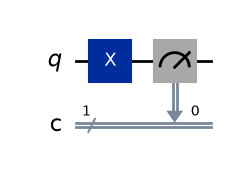

Circuit B (X, X)


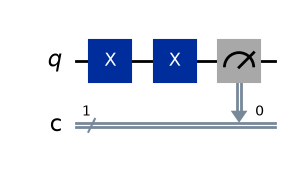

Circuit C (H)


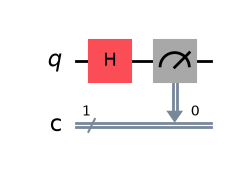

In [2]:
# Circuit A: X then measure
qc_a = QuantumCircuit(1, 1, name="Circuit A")
qc_a.x(0)
qc_a.measure(0, 0)

# Circuit B: X, X then measure
qc_b = QuantumCircuit(1, 1, name="Circuit B")
qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)

# Circuit C: H then measure
qc_c = QuantumCircuit(1, 1, name="Circuit C")
qc_c.h(0)
qc_c.measure(0, 0)

circuits = {"A (X)": qc_a, "B (X, X)": qc_b, "C (H)": qc_c}
for label, qc in circuits.items():
    print(f"Circuit {label}")
    display(qc.draw("mpl"))

## 4. Execute each circuit for 100 shots

In [3]:
results = {}
for label, qc in circuits.items():
    compiled = transpile(qc, backend)
    job = backend.run(compiled, shots=SHOTS)
    results[label] = job.result().get_counts()
    print(f"Circuit {label}: {results[label]}")

Circuit A (X): {'1': 100}
Circuit B (X, X): {'0': 100}
Circuit C (H): {'0': 63, '1': 37}


## 5. Histograms

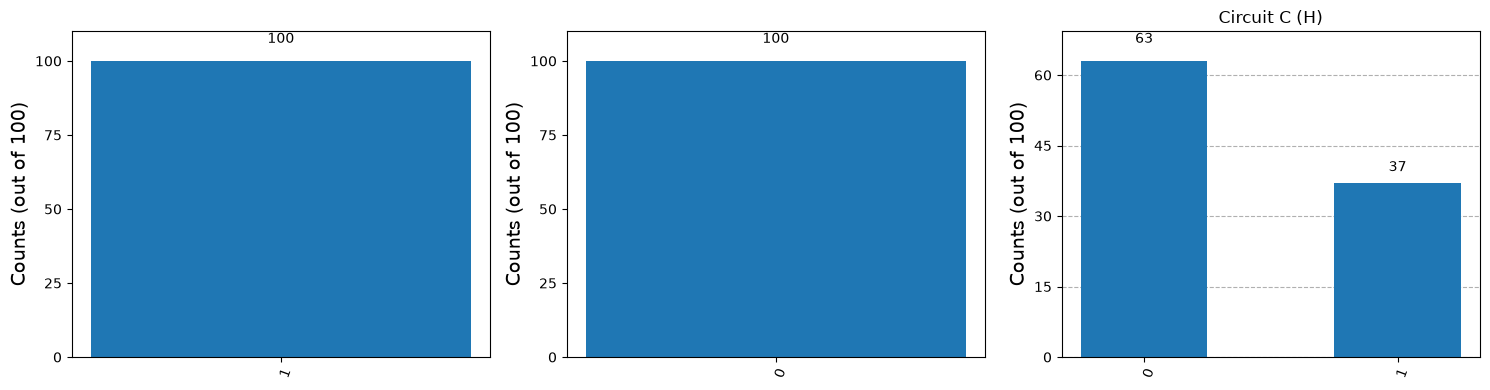

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (label, counts) in zip(axes, results.items()):
    plot_histogram(counts, ax=ax, title=f"Circuit {label}", bar_labels=True)
    ax.set_ylabel("Counts (out of 100)")
plt.tight_layout()
plt.show()

## 6. Prediction vs. actual

In [5]:
predictions = {
    "A (X)":    {"0": 0,  "1": 100},
    "B (X, X)": {"0": 100, "1": 0},
    "C (H)":    {"0": 50, "1": 50},
}

print(f"{'Circuit':<10}{'Predicted 0/1':<16}{'Actual 0/1':<14}")
for label in circuits:
    p = predictions[label]
    a = results[label]
    print(f"{label:<10}{str(p['0'])+' / '+str(p['1']):<16}{str(a.get('0',0))+' / '+str(a.get('1',0)):<14}")

Circuit   Predicted 0/1   Actual 0/1    
A (X)     0 / 100         0 / 100       
B (X, X)  100 / 0         100 / 0       
C (H)     50 / 50         63 / 37       


## 7. Comparison and conclusion

- **Circuit A:** the result matched the prediction: all 100 shots gave `1`. X flips |0⟩ to |1⟩ deterministically.
- **Circuit B:** also matched: all 100 shots gave `0`. Two X gates cancel out (X² = I), so the qubit returns to |0⟩.
- **Circuit C:** the counts were close to 50/50 but not exactly 50/50 (e.g. 47/53). This agrees with the prediction: H creates an equal superposition, and measurement collapses it randomly to `0` or `1` with 50% probability each. The small deviation is ordinary statistical fluctuation from using only 100 shots. Re-running the cell gives different counts each time, and more shots would bring the ratio closer to 50/50.

**Takeaway:** X and X·X are deterministic, while H produces probabilistic outcomes. Superposition is what makes Circuit C different from the other two.